<a href="https://colab.research.google.com/github/LLoghan/analise-preco-jogos/blob/main/Preco_Jogos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Estatísticas por Plataforma ===
             count    mean  median    min    max    std
Steam        317.0  150.00   129.0  26.49  359.0  94.46
PlayStation  289.0  200.08   199.5  42.50  359.9  89.80
Xbox         266.0  173.77   149.0  19.00  359.0  99.54
Nintendo     172.0  178.05   160.0  36.99  350.0  79.83
Epic Games   148.0  157.05   149.0  28.99  359.0  93.69


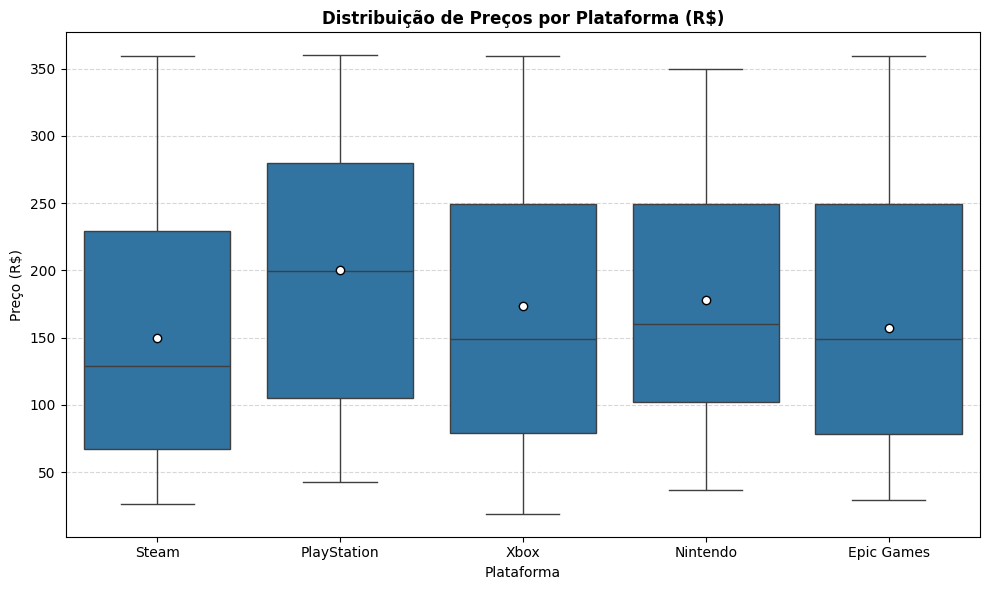

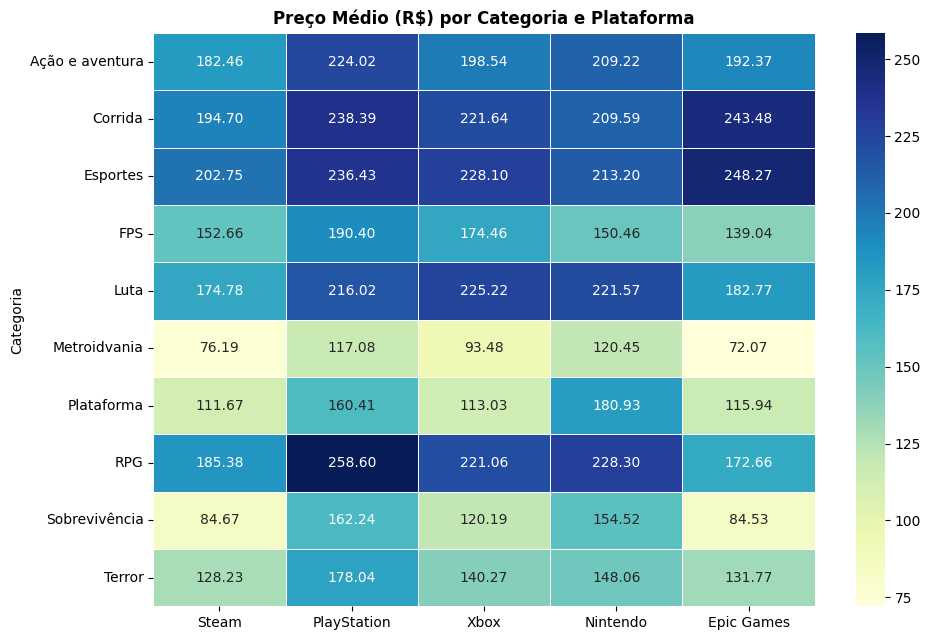

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Carregamento dos dados e limpeza dos nomes das colunas
df = pd.read_csv('Preco_Jogos.csv')
df.columns = df.columns.str.strip()

colunas_preco = [
    'Preço Steam', 'Preço Playstation', 'Preço Xbox',
    'Preço Nintendo', 'Preço EpicGames'
]

#Função para higienizar strings e converter para float
def limpar_preco(valor):
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip()
    if 'não disponível' in texto.lower() or texto == '':
        return np.nan
    #Remove anotações entre parênteses, ex: (Switch 2) ou (Incluído Game Pass)
    texto = re.sub(r'\(.*?\)', '', texto)
    texto = texto.replace('R$', '').strip()
    #Ajusta separador decimal brasileiro
    if ',' in texto and '.' in texto:
        texto = texto.replace('.', '').replace(',', '.')
    elif ',' in texto:
        texto = texto.replace(',', '.')
    try:
        return float(texto)
    except ValueError:
        return np.nan

for col in colunas_preco:
    df[col] = df[col].apply(limpar_preco)

#Renomeia colunas para exibição limpa nos gráficos
mapa_nomes = {
    'Preço Steam': 'Steam',
    'Preço Playstation': 'PlayStation',
    'Preço Xbox': 'Xbox',
    'Preço Nintendo': 'Nintendo',
    'Preço EpicGames': 'Epic Games'
}
df_plot = df.rename(columns=mapa_nomes)
plataformas = list(mapa_nomes.values())

#Exibição do resumo estatístico no terminal
estatisticas = df_plot[plataformas].agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
print("=== Estatísticas por Plataforma ===")
print(estatisticas.round(2))

#Gráfico 1: Boxplot de Distribuição de Preços por Plataforma
df_longo = df_plot.melt(
    id_vars=['Jogo', 'Categoria'],
    value_vars=plataformas,
    var_name='Plataforma',
    value_name='Preço (R$)'
).dropna(subset=['Preço (R$)'])

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_longo, x='Plataforma', y='Preço (R$)',
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
)
plt.title('Distribuição de Preços por Plataforma (R$)', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('distribuicao_precos.png', dpi=300)
plt.show()

#Gráfico 2: Mapa de Calor (Categoria x Plataforma)
plt.figure(figsize=(10, 6.5))
tabela_media = df_plot.groupby('Categoria')[plataformas].mean().round(2)
sns.heatmap(tabela_media, annot=True, fmt='.2f', cmap='YlGnBu', linewidths=0.5)
plt.title('Preço Médio (R$) por Categoria e Plataforma', fontweight='bold')
plt.tight_layout()
plt.savefig('mapa_calor_categorias.png', dpi=300)
plt.show()